# Data cleaning – Parkinson's voice dataset

Week 2 · Maxence Périnel, Octave Goudon

FR – Dans ce notebook on cherche les problèmes des données brutes, on les corrige, puis on vérifie que c'est bien réglé. À la fin on regarde les données propres avec quelques graphiques. On sauvegarde deux fichiers : `data/processed/pd_speech_clean.csv` (toutes les features de voix) et `data/processed/pd_speech_reduced.csv` (sans les features qui sont des copies les unes des autres).

EN – In this notebook we look for problems in the raw data, fix them, and check that they are really gone. At the end we look at the clean data with a few graphs. We save two files: `data/processed/pd_speech_clean.csv` (all voice features) and `data/processed/pd_speech_reduced.csv` (without the features that are copies of each other).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Step 1 – Load the data

FR – On lit le fichier normalement et on regarde le nom des colonnes.

EN – We read the file the normal way and look at the column names.

In [2]:
test = pd.read_csv("../data/raw/pd_speech_features.csv")
print(test.columns[:6].tolist())
test.head(2)

['Unnamed: 0', 'Unnamed: 1', 'Baseline Features', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5']


,Unnamed: 0,Unnamed: 1,Baseline Features,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 745,Unnamed: 746,Unnamed: 747,Unnamed: 748,Unnamed: 749,Unnamed: 750,Unnamed: 751,Unnamed: 752,Unnamed: 753,Unnamed: 754
0,id,gender,PPE,DFA,RPDE,numPulses,numPeriodsPulses,meanPeriodPulses,stdDevPeriodPulses,locPctJitter,...,tqwt_kurtosisValue_dec_28,tqwt_kurtosisValue_dec_29,tqwt_kurtosisValue_dec_30,tqwt_kurtosisValue_dec_31,tqwt_kurtosisValue_dec_32,tqwt_kurtosisValue_dec_33,tqwt_kurtosisValue_dec_34,tqwt_kurtosisValue_dec_35,tqwt_kurtosisValue_dec_36,class
1,0,1,0.85247,0.71826,0.57227,240,239,0.00806353,8.68E-05,0.00218,...,1.562,2.6445,3.8686,4.2105,5.1221,4.4625,2.6202,3.0004,18.9405,1


FR – Les colonnes s'appellent `Unnamed: 0`, `Unnamed: 1`, ... et la première ligne contient les vrais noms (`id`, `gender`, `PPE`). Le fichier a donc deux lignes d'en-tête : la première donne la famille de features et la seconde les noms. On relit le fichier avec `header=1`.

EN – The columns are called `Unnamed: 0`, `Unnamed: 1`, ... and the first row contains the real names (`id`, `gender`, `PPE`). The file has two header rows: the first one gives the feature family and the second one the names. We read the file again with `header=1`.

In [3]:
df = pd.read_csv("../data/raw/pd_speech_features.csv", header=1)
print(df.columns[:6].tolist())
print(df.shape)

['id', 'gender', 'PPE', 'DFA', 'RPDE', 'numPulses']
(756, 755)


FR – Les colonnes ont maintenant leurs vrais noms. On a 756 lignes (enregistrements) et 755 colonnes.

EN – The columns now have their real names. We have 756 rows (recordings) and 755 columns.

In [4]:
print("Number of people:", df["id"].nunique())
print("Recordings per person:", df["id"].value_counts().unique())
print(df["class"].value_counts())

Number of people: 252
Recordings per person: [3]
class
1    564
0    192
Name: count, dtype: int64


FR – On a 252 personnes avec 3 enregistrements chacune, 564 enregistrements Parkinson (classe 1) et 192 sains (classe 0).

EN – We have 252 people with 3 recordings each, 564 Parkinson recordings (class 1) and 192 healthy ones (class 0).

## Step 2 – Missing values and data types

FR – On compte les valeurs manquantes de chaque colonne et on vérifie que tout est numérique.

EN – We count the missing values in each column and check that everything is numeric.

In [5]:
missing = df.isna().sum()
print("Columns with missing values:", (missing > 0).sum())
print("Total missing values:", missing.sum())
print(df.dtypes.value_counts())

Columns with missing values: 0
Total missing values: 0
float64    749
int64        6
Name: count, dtype: int64


FR – Il n'y a aucune valeur manquante et toutes les colonnes sont des nombres (`int64` ou `float64`). Il n'y a rien à corriger ici.

EN – There are no missing values and all columns are numbers (`int64` or `float64`). Nothing to fix here.

## Step 3 – Duplicated rows

FR – On cherche les lignes qui apparaissent deux fois.

EN – We look for rows that appear twice.

In [6]:
print("Duplicated rows:", df.duplicated().sum())
df[df.duplicated(keep=False)][["id", "gender", "class", "PPE", "DFA", "RPDE"]]

Duplicated rows: 1


,id,gender,class,PPE,DFA,RPDE
111,37,0,1,0.79067,0.58465,0.6425
113,37,0,1,0.79067,0.58465,0.6425


FR – Il y a 1 ligne dupliquée : la personne 37 a deux enregistrements identiques (lignes 111 et 113), avec les mêmes 755 valeurs. Deux vrais enregistrements ne donneraient jamais exactement les mêmes nombres, donc c'est sûrement une erreur de copie. On garde une seule copie.

EN – There is 1 duplicated row: person 37 has two identical recordings (rows 111 and 113), with the same 755 values. Two real recordings would never give exactly the same numbers, so it is most likely a copy error. We keep only one copy.

In [7]:
df = df.drop_duplicates()
print("Duplicated rows:", df.duplicated().sum())
print("Recordings of person 37:", (df["id"] == 37).sum())
print(df.shape)

Duplicated rows: 0
Recordings of person 37: 2
(755, 755)


FR – Il reste 0 ligne dupliquée. La personne 37 a maintenant 2 enregistrements au lieu de 3.

EN – There are 0 duplicated rows left. Person 37 now has 2 recordings instead of 3.

## Step 4 – Is the information consistent for each person?

FR – Une personne doit avoir le même label (`class`) et le même `gender` dans tous ses enregistrements, on le teste.

EN – One person must have the same label (`class`) and the same `gender` in all their recordings, so we test it.

In [8]:
print("People with 2 different labels:", (df.groupby("id")["class"].nunique() > 1).sum())
print("People with 2 different genders:", (df.groupby("id")["gender"].nunique() > 1).sum())

People with 2 different labels: 0
People with 2 different genders: 0


FR – On trouve 0 et 0 : les labels et les genres sont cohérents. Il n'y a rien à corriger.

EN – We get 0 and 0: the labels and genders are consistent. Nothing to fix.

## Step 5 – Useless columns

FR – Une colonne qui ne varie presque pas n'apporte rien. On calcule l'écart-type (std) de chaque colonne et on regarde les plus petits.

EN – A column that almost never changes gives nothing. We compute the standard deviation (std) of each column and look at the smallest ones.

In [9]:
std = df.drop(columns=["id", "class"]).std().sort_values()
std.head(40)

tqwt_meanValue_dec_2      5.721531e-21
tqwt_meanValue_dec_1      6.467929e-21
tqwt_meanValue_dec_3      7.032174e-21
tqwt_meanValue_dec_4      8.665998e-21
tqwt_meanValue_dec_5      9.284775e-21
tqwt_meanValue_dec_6      1.402701e-20
tqwt_meanValue_dec_7      2.704248e-20
tqwt_meanValue_dec_8      2.864892e-20
tqwt_meanValue_dec_9      3.556233e-20
tqwt_meanValue_dec_10     3.905105e-20
tqwt_meanValue_dec_11     8.348372e-20
tqwt_meanValue_dec_12     1.368272e-19
tqwt_meanValue_dec_13     2.389621e-19
tqwt_meanValue_dec_16     3.432083e-19
tqwt_meanValue_dec_20     3.876910e-19
tqwt_meanValue_dec_17     4.172606e-19
tqwt_meanValue_dec_14     4.345096e-19
tqwt_meanValue_dec_31     4.912694e-19
tqwt_meanValue_dec_30     4.942510e-19
tqwt_meanValue_dec_35     5.211043e-19
tqwt_meanValue_dec_34     5.413257e-19
tqwt_meanValue_dec_15     7.042134e-19
tqwt_meanValue_dec_29     9.305524e-19
tqwt_meanValue_dec_24     9.443142e-19
tqwt_meanValue_dec_32     9.874834e-19
tqwt_meanValue_dec_25    

FR – Il y a un gros saut dans la liste : 35 colonnes (`tqwt_meanValue_dec_1` à `dec_35`) ont un std d'environ 1e-20 à 1e-18, et la colonne suivante est à environ 3e-6. Regardons les valeurs de l'une de ces colonnes :

EN – There is a big jump in the list: 35 columns (`tqwt_meanValue_dec_1` to `dec_35`) have a std of about 1e-20 to 1e-18, and the next column is at about 3e-6. Let's look at the values of one of these columns:

In [10]:
df["tqwt_meanValue_dec_1"].head()

0   -2.890000e-21
1   -1.770000e-21
2    9.440000e-22
3   -4.480000e-21
4   -1.800000e-21
Name: tqwt_meanValue_dec_1, dtype: float64

FR – Les valeurs sont autour de 0,000000000000000000001, ce qui ressemble à du bruit d'arrondi de l'ordinateur et pas à une vraie mesure. Si on les gardait, la normalisation les agrandirait et elles ressembleraient à une vraie feature. On supprime donc les colonnes dont le std est inférieur à 1e-12, très en dessous de toutes les autres.

EN – The values are around 0.000000000000000000001, which looks like rounding noise from the computer and not a real measure. If we kept them, the scaling would blow them up and they would look like a real feature. So we remove the columns with a std below 1e-12, far below all the others.

In [11]:
useless = std[std < 1e-12].index
print(len(useless), "columns removed")
df = df.drop(columns=useless)
print(df.shape)

35 columns removed
(755, 720)


In [12]:
print("Smallest std now:", df.drop(columns=["id", "class"]).std().min())

Smallest std now: 3.0096094027273675e-06


FR – Le plus petit std est maintenant d'environ 3e-6, une vraie valeur. On passe de 755 à 720 colonnes (755 − 35).

EN – The smallest std is now about 3e-6, a real value. We go from 755 to 720 columns (755 − 35).

## Step 6 – Final check

FR – On relance tous les tests sur les données propres. Les `assert` arrêtent le notebook avec une erreur si un test échoue.

EN – We run all the tests again on the clean data. The `assert` lines stop the notebook with an error if a test fails.

In [13]:
assert df.isna().sum().sum() == 0, "there are missing values"
assert df.duplicated().sum() == 0, "there are duplicated rows"
assert (df.groupby("id")["class"].nunique() == 1).all(), "a person has 2 labels"
assert df.drop(columns=["id", "class"]).std().min() > 1e-12, "there are useless columns"
print("All tests passed. Clean data:", df.shape)

All tests passed. Clean data: (755, 720)


FR – Les données étaient déjà en bon état : pas de valeur manquante et des labels cohérents. On a seulement enlevé 1 ligne dupliquée et 35 colonnes de bruit. On passe de 756 à 755 enregistrements, on garde 252 personnes et on a 720 colonnes (`id`, `class`, `gender` et 717 features de voix).

EN – The data was already in good shape: no missing values and consistent labels. We only removed 1 duplicated row and 35 noise columns. We go from 756 to 755 recordings, we keep 252 people and we have 720 columns (`id`, `class`, `gender` and 717 voice features).

## Step 7 – Look at the clean data

### 7.1 How many Parkinson and healthy recordings?

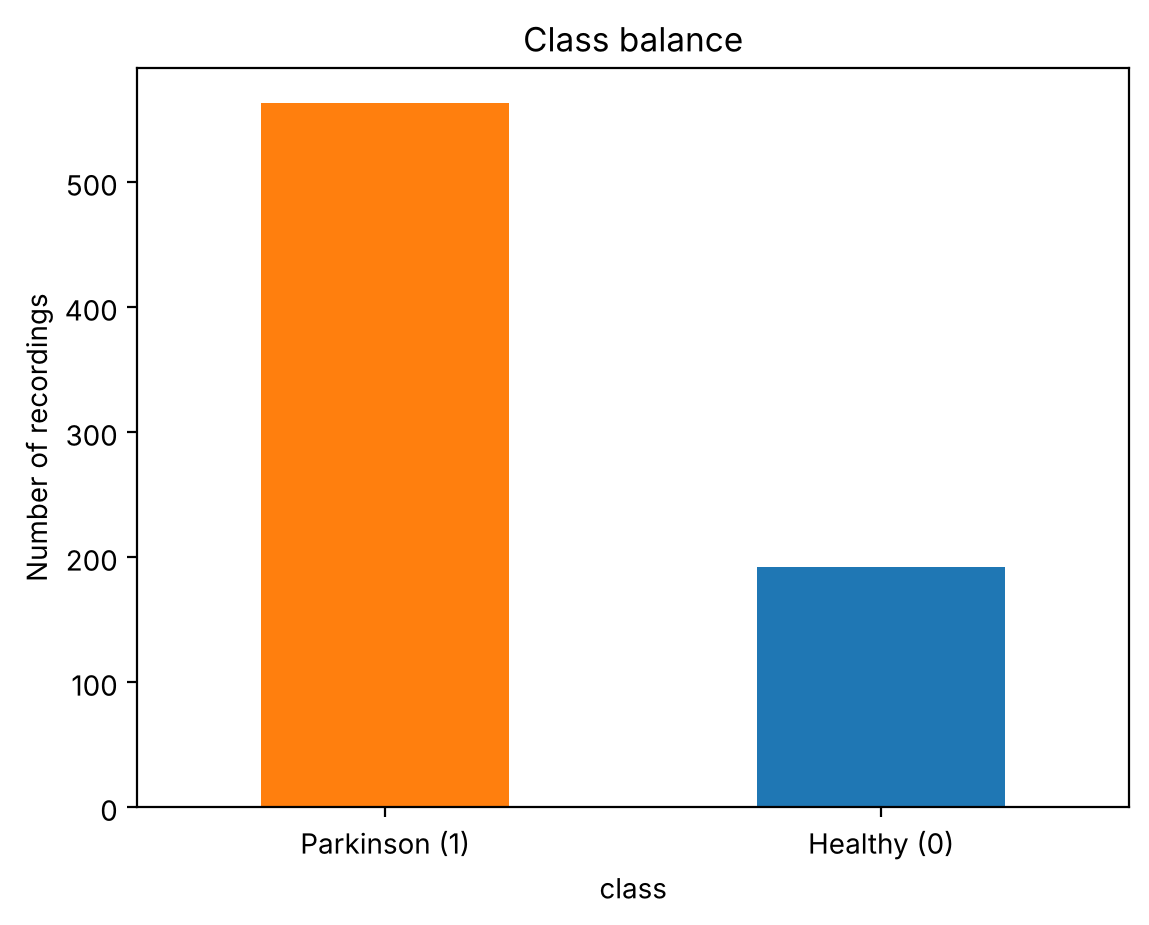

class
1    0.75
0    0.25
Name: proportion, dtype: float64


In [14]:
df["class"].value_counts().plot(kind="bar", color=["tab:orange", "tab:blue"])
plt.xticks([0, 1], ["Parkinson (1)", "Healthy (0)"], rotation=0)
plt.ylabel("Number of recordings")
plt.title("Class balance")
plt.show()
print(df["class"].value_counts(normalize=True).round(2))

FR – On a 75 % de Parkinson et 25 % de sains : les classes sont déséquilibrées. Un modèle qui répond toujours « Parkinson » aurait raison 75 % du temps, donc on ne jugera pas les modèles sur l'accuracy seule.

EN – We have 75% Parkinson and 25% healthy: the classes are imbalanced. A model that always says "Parkinson" would be right 75% of the time, so we will not judge the models on accuracy alone.

### 7.2 Do some voice measures look different for Parkinson patients?

FR – Le jitter et le shimmer ont quelques très grandes valeurs, donc on les met en échelle logarithmique. Sinon les boîtes sont écrasées en bas du graphique.

EN – Jitter and shimmer have a few very large values, so we use a log scale for them. Otherwise the boxes are squashed at the bottom of the graph.

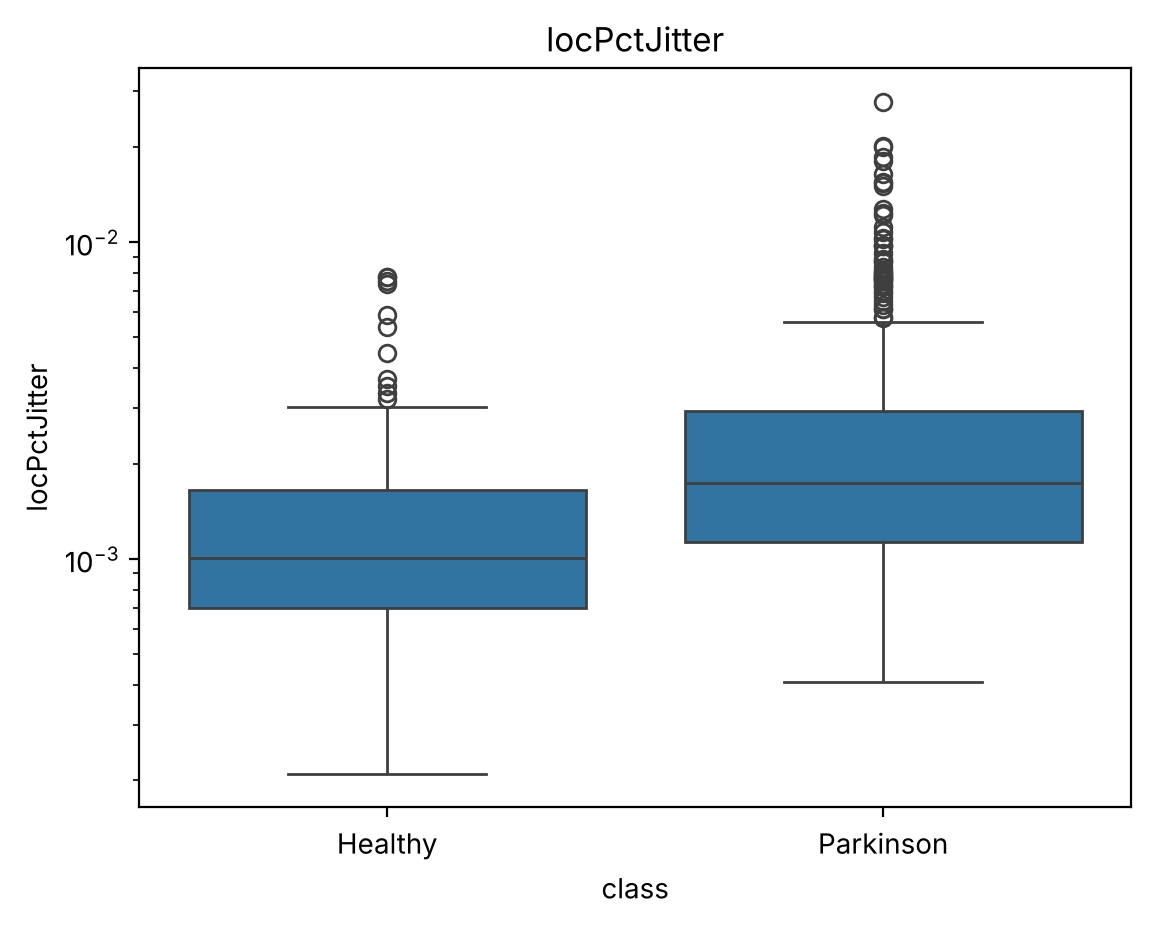

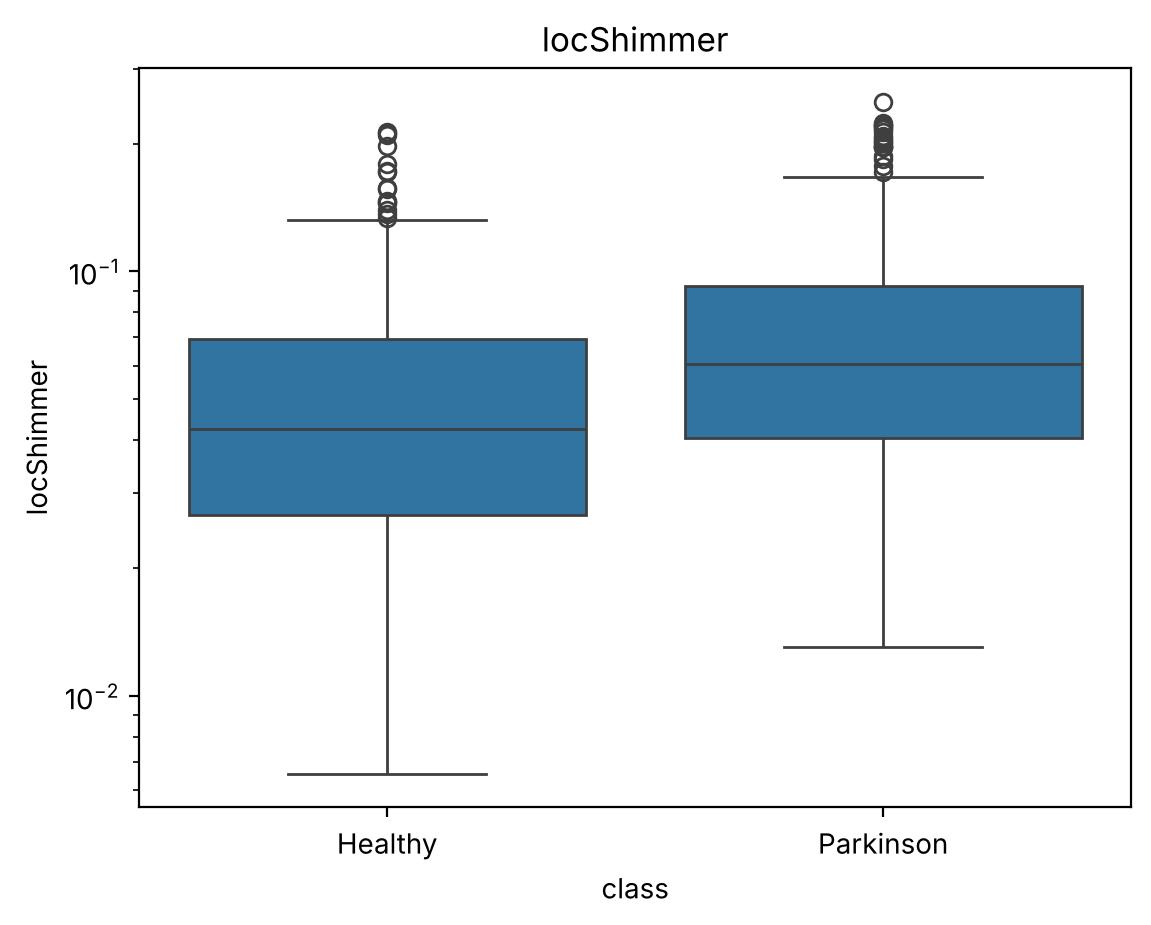

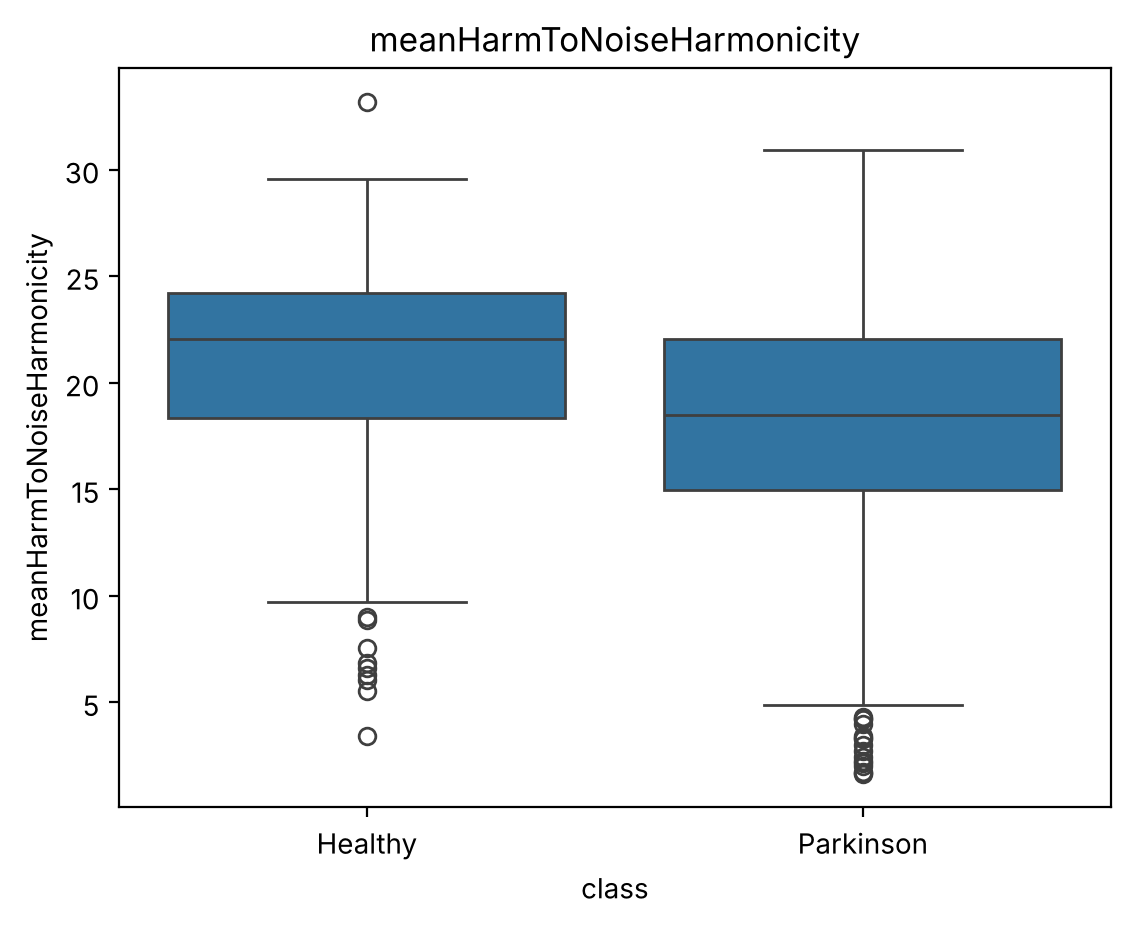

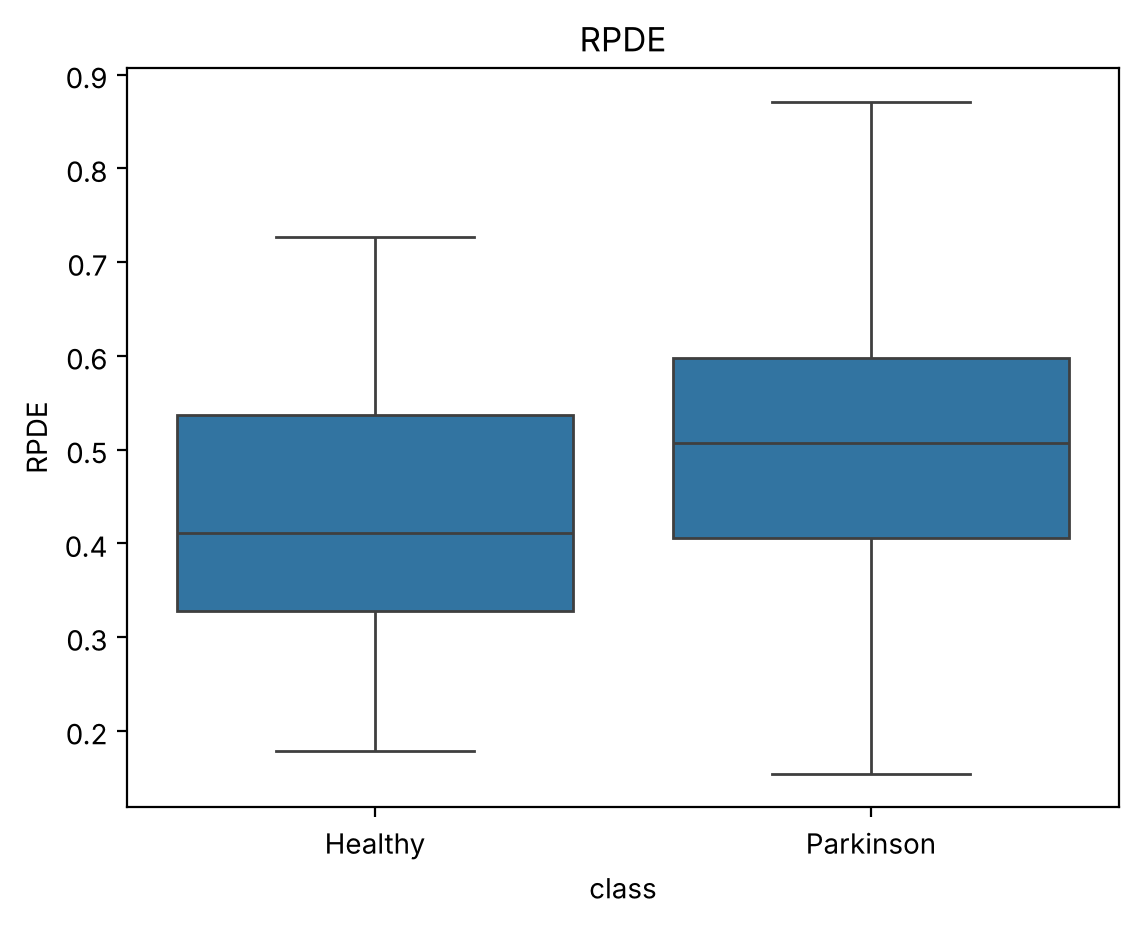

In [15]:
for feature in ["locPctJitter", "locShimmer", "meanHarmToNoiseHarmonicity", "RPDE"]:
    sns.boxplot(data=df, x="class", y=feature)
    plt.xticks([0, 1], ["Healthy", "Parkinson"])
    if feature in ["locPctJitter", "locShimmer"]:
        plt.yscale("log")
    plt.title(feature)
    plt.show()

In [16]:
# Check with numbers: median of each measure per class
df.groupby("class")[["locPctJitter", "locShimmer", "meanHarmToNoiseHarmonicity", "RPDE"]].median()

,locPctJitter,locShimmer,meanHarmToNoiseHarmonicity,RPDE
class,,,,
0,0.001005,0.04260,22.044,0.41123
1,0.001730,0.06054,18.502,0.50686


FR – D'après les médianes, le jitter (0,00173 contre 0,00101), le shimmer (0,0605 contre 0,0426) et le RPDE (0,507 contre 0,411) sont plus élevés chez les malades, et le rapport harmoniques/bruit est plus bas (18,5 contre 22,0). Cela peut correspondre à une voix plus instable et plus soufflée. Mais les boîtes se chevauchent beaucoup : aucune mesure seule ne suffit, le modèle devra en combiner plusieurs.

EN – According to the medians, jitter (0.00173 against 0.00101), shimmer (0.0605 against 0.0426) and RPDE (0.507 against 0.411) are higher for patients, and the harmonics-to-noise ratio is lower (18.5 against 22.0). This can fit a voice that is less stable and more breathy. But the boxes overlap a lot: no single measure is enough, so the model will have to combine several.

### 7.3 Are the features linked to each other?

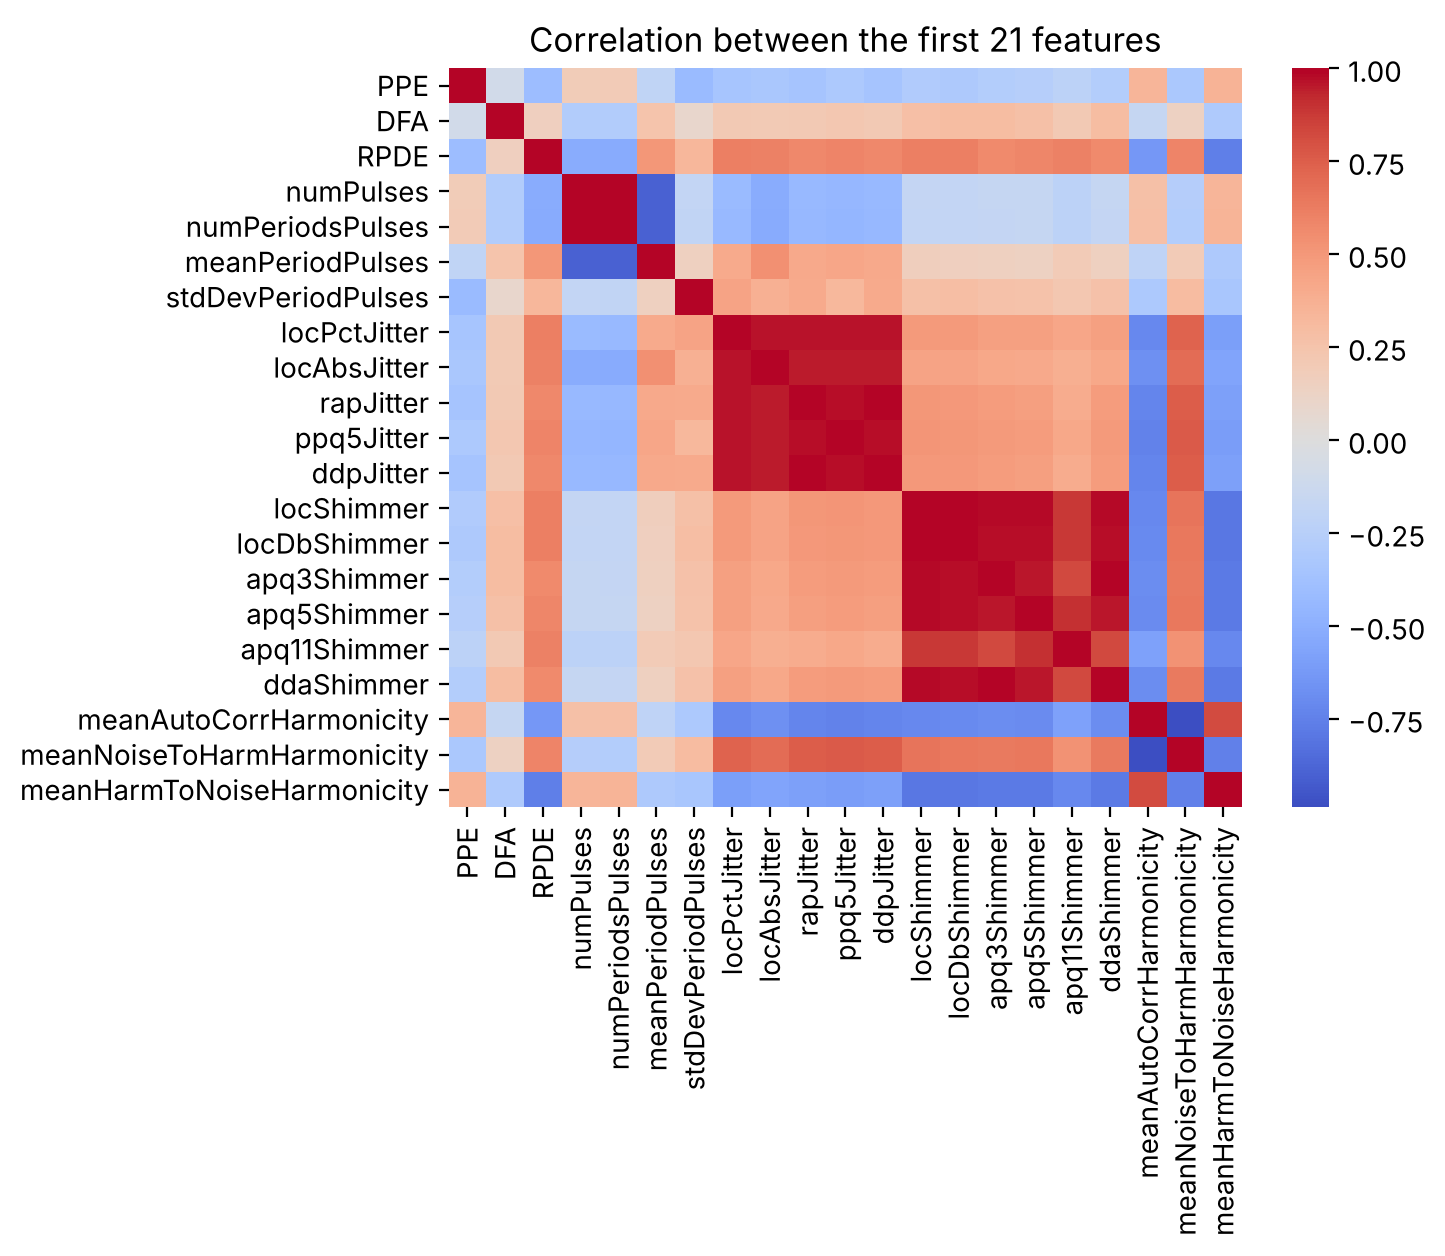

In [17]:
first_features = df.columns[2:23]       # the 21 "baseline" voice features
sns.heatmap(df[first_features].corr(), cmap="coolwarm", center=0)
plt.title("Correlation between the first 21 features")
plt.show()

In [18]:
# Check with a number: correlation between two jitter measures
print(df["rapJitter"].corr(df["ddpJitter"]))

0.9999961830306565


FR – Les carrés rouges de la heatmap sont des groupes de features qui mesurent presque la même chose. Par exemple `rapJitter` et `ddpJitter` ont une corrélation de 0,999996, donc la même information. Beaucoup de features sont redondantes, on s'en occupe à l'étape 9.

EN – The red squares in the heatmap are groups of features that measure almost the same thing. For example `rapJitter` and `ddpJitter` have a correlation of 0.999996, so they carry the same information. Many features are redundant, and we deal with them in step 9.

### 7.4 Are the recordings of one person similar?

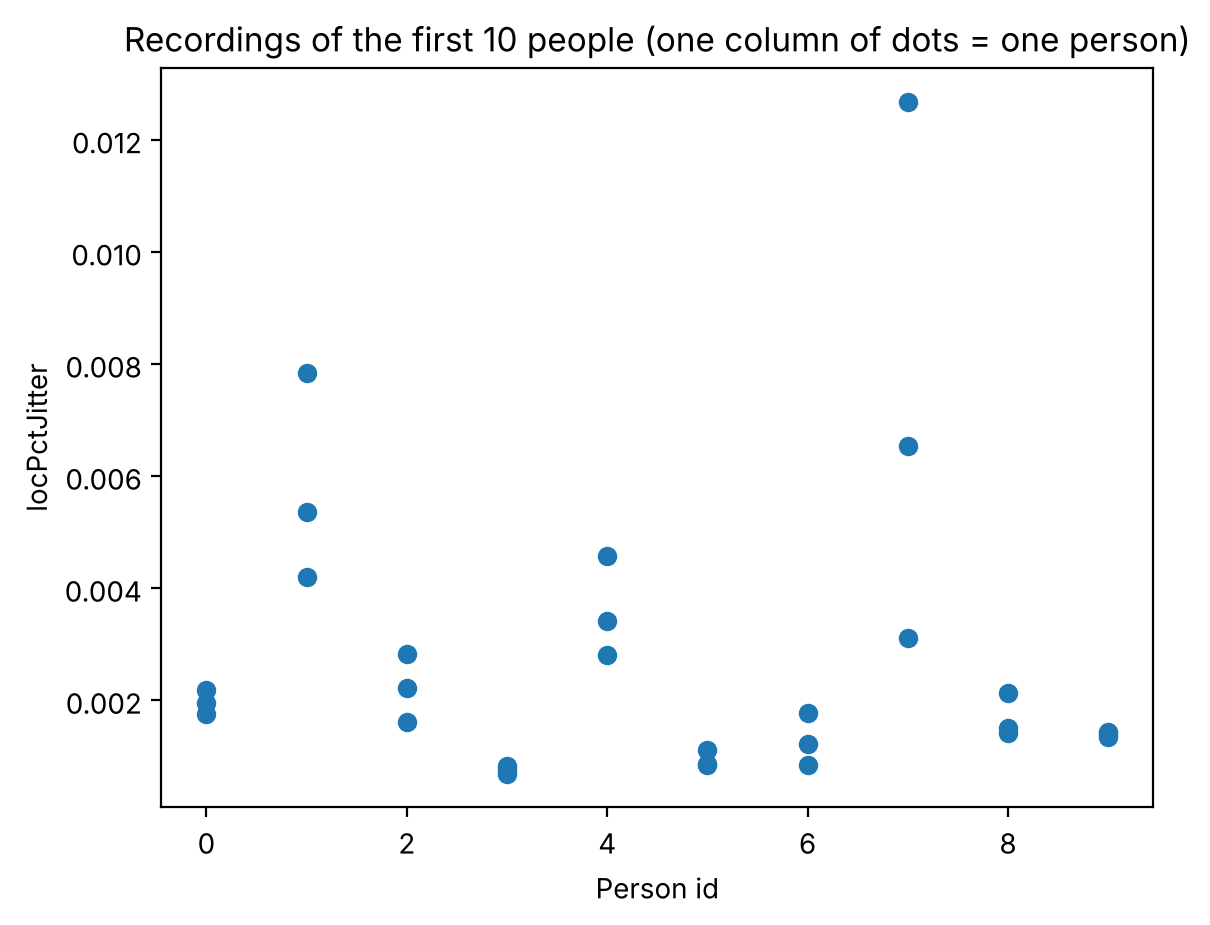

In [19]:
ten_people = df[df["id"] < 10]
plt.scatter(ten_people["id"], ten_people["locPctJitter"])
plt.xlabel("Person id")
plt.ylabel("locPctJitter")
plt.title("Recordings of the first 10 people (one column of dots = one person)")
plt.show()

In [20]:
# Check with numbers: spread inside one person vs spread between people
spread_inside = df.groupby("id")["locPctJitter"].std().mean()
spread_between = df.groupby("id")["locPctJitter"].mean().std()
print("Average spread inside one person:", round(spread_inside, 5))
print("Spread between people:          ", round(spread_between, 5))

Average spread inside one person: 0.0008
Spread between people:           0.00238


FR – Les points d'une même personne sont en général proches les uns des autres. Les chiffres vont dans le même sens : l'écart moyen à l'intérieur d'une personne est 0,0008, contre 0,00238 entre les personnes. Si un enregistrement est dans l'entraînement et un autre de la même personne dans le test, le modèle peut reconnaître la personne au lieu de la maladie. On sépare donc les données par personne, comme dans `baseline.ipynb`.

EN – The dots of one person are usually close to each other. The numbers go the same way: the average spread inside one person is 0.0008, against 0.00238 between people. If one recording is in the training set and another one of the same person is in the test set, the model can recognise the person instead of the disease. So we split the data by person, as in `baseline.ipynb`.

## Step 8 – Features that barely change

FR – À l'étape 5 on a enlevé 35 colonnes de bruit. On regarde s'il reste des features qui changent très peu, en comptant leurs valeurs différentes (sans `id`, `class` et `gender`). Une colonne avec très peu de valeurs différentes n'apporterait presque rien.

EN – In step 5 we removed 35 noise columns. We check if other features barely change, by counting their different values (without `id`, `class` and `gender`). A column with very few different values would give almost nothing.

In [21]:
voice_features = df.drop(columns=["id", "class", "gender"])
print("Voice features:", voice_features.shape[1])
voice_features.nunique().sort_values().head(5)

Voice features: 717


Ea2           103
rapJitter     183
Ea            227
ppq5Jitter    244
numPulses     315
dtype: int64

FR – La plus petite est `Ea2`, avec 103 valeurs différentes sur 755 enregistrements, donc aucune colonne n'est presque constante et on ne supprime rien. Une feature avec de petits nombres (comme le jitter, autour de 0,001) n'est pas pour autant inutile : on normalisera toutes les features avant de modéliser.

EN – The smallest one is `Ea2`, with 103 different values out of 755 recordings, so no column is almost constant and we remove nothing. A feature with small numbers (like jitter, around 0.001) is not useless for that reason: we will scale all the features before modelling.

## Step 9 – Features that are copies of each other

FR – La heatmap de l'étape 7.3 montrait des features qui évoluent ensemble. Quand deux features sont presque parfaitement corrélées, l'une des deux est inutile. On écrit une petite fonction qui trouve, pour un seuil donné, les colonnes trop corrélées avec une colonne située avant elles, et on compte combien seraient supprimées pour 3 seuils.

EN – The heatmap in step 7.3 showed features that move together. When two features are almost perfectly correlated, one of them is useless. We write a small function that finds, for a given threshold, the columns that are too correlated with a column before them, and we count how many would be removed for 3 thresholds.

In [22]:
def columns_to_remove(data, threshold):
    corr = data.corr().abs().values          # table of the correlations between all pairs of columns
    names = list(data.columns)
    to_remove = []
    for j in range(len(names)):              # for each column j...
        for i in range(j):                   # ...we look at the columns before it
            if corr[i, j] > threshold:       # if j is a near-copy of an earlier column,
                to_remove.append(names[j])   # we remove j (we keep the first of the two)
                break
    return to_remove

for threshold in [0.99, 0.95, 0.90]:
    print(f"correlation > {threshold}: {len(columns_to_remove(voice_features, threshold))} columns to remove")

correlation > 0.99: 97 columns to remove


correlation > 0.95: 241 columns to remove


correlation > 0.9: 364 columns to remove


In [23]:
# Some examples of pairs
print("apq3Shimmer vs ddaShimmer:", round(voice_features["apq3Shimmer"].corr(voice_features["ddaShimmer"]), 4))
print("rapJitter vs ddpJitter:", round(voice_features["rapJitter"].corr(voice_features["ddpJitter"]), 4))
print("entropy coefficient 8 vs 9:", round(voice_features["app_entropy_log_8_coef"].corr(voice_features["app_entropy_log_9_coef"]), 4))

# ddaShimmer should be exactly 3 times apq3Shimmer
(df["ddaShimmer"] / df["apq3Shimmer"]).describe()[["min", "max"]]

apq3Shimmer vs ddaShimmer: 1.0
rapJitter vs ddpJitter: 1.0
entropy coefficient 8 vs 9: 1.0


min    2.997015
max    3.001724
dtype: float64

FR – Avec un seuil de 0,99 on supprimerait 97 colonnes, avec 0,95 on en supprimerait 241 et avec 0,90 on en supprimerait 364. Les exemples sont de vraies copies : `ddaShimmer` vaut 3 fois `apq3Shimmer` (le rapport reste entre 2,997 et 3,002) et `ddpJitter` est presque identique à `rapJitter`. On supprime les colonnes au-dessus de 0,99 en gardant la première de chaque groupe, et on teste les seuils 0,95 et 0,90 avec un modèle dans `baseline.ipynb`, car ils pourraient enlever de la vraie information.

EN – With a threshold of 0.99 we would remove 97 columns, with 0.95 we would remove 241 and with 0.90 we would remove 364. The examples are real copies: `ddaShimmer` is 3 times `apq3Shimmer` (the ratio stays between 2.997 and 3.002) and `ddpJitter` is almost the same as `rapJitter`. We remove the columns above 0.99 and keep the first one of each group, and we test the thresholds 0.95 and 0.90 with a model in `baseline.ipynb`, because they could remove real information.

In [24]:
to_remove = columns_to_remove(voice_features, 0.99)
reduced = df.drop(columns=to_remove)
print(len(to_remove), "columns removed")
print(reduced.shape)

97 columns removed
(755, 623)


In [25]:
# Check: no pair is above 0.99 anymore, and the features of our graphs are still there
corr_after = reduced.drop(columns=["id", "class", "gender"]).corr().abs().values.copy()
np.fill_diagonal(corr_after, 0)          # a column is always correlated 1 with itself: we ignore that
print("Highest correlation left:", round(corr_after.max(), 4))
for feature in ["locPctJitter", "locShimmer", "meanHarmToNoiseHarmonicity", "RPDE"]:
    print(feature, "is still there:", feature in reduced.columns)

Highest correlation left: 0.9899
locPctJitter is still there: True
locShimmer is still there: True
meanHarmToNoiseHarmonicity is still there: True
RPDE is still there: True


FR – La corrélation la plus haute qui reste est 0,9899, donc plus rien n'est au-dessus de 0,99, et nos 4 features des graphiques sont toujours là. On a gardé `rapJitter` et `apq3Shimmer` et supprimé `ddpJitter` et `ddaShimmer`, qui disent la même chose.

EN – The highest correlation left is 0.9899, so nothing is above 0.99 anymore, and our 4 graph features are still there. We kept `rapJitter` and `apq3Shimmer` and removed `ddpJitter` and `ddaShimmer`, which say the same thing.

### Does this choice depend on the people we used?

FR – On a choisi les colonnes avec les 252 personnes, sans utiliser les labels. Mais une partie des personnes servira de jeu de test, et un choix fait avec elles pourrait un peu aider le score final. On refait donc le choix avec seulement la moitié des personnes (id pairs, puis id impairs) et on compare les listes.

EN – We chose the columns using all 252 people, without using the labels. But some of the people will be our test set, and a choice made with them could slightly help the final score. So we make the choice again with only half of the people (even ids, then odd ids) and compare the lists.

In [26]:
people = df["id"].unique()
half_a = voice_features[df["id"].isin(people[::2])]       # every second person
half_b = voice_features[df["id"].isin(people[1::2])]      # the other people

remove_a = set(columns_to_remove(half_a, 0.99))
remove_b = set(columns_to_remove(half_b, 0.99))
print("Removed with half A:", len(remove_a), "| with half B:", len(remove_b))
print("Removed in both halves:", len(remove_a & remove_b))
print("Removed in at least one half:", len(remove_a | remove_b))
print("Columns of our list found in at least one half:", len(set(to_remove) & (remove_a | remove_b)), "/", len(to_remove))

Removed with half A: 113 | with half B: 97
Removed in both halves: 81
Removed in at least one half: 129
Columns of our list found in at least one half: 97 / 97


FR – 81 colonnes sont supprimées avec les deux moitiés, et les 97 colonnes de notre liste apparaissent dans au moins une moitié. Les deux listes ne sont pas identiques, probablement à cause de paires dont la corrélation est proche de 0,99, donc le choix dépend un peu des personnes. Par prudence, `baseline.ipynb` refait le filtre sur les personnes d'entraînement seulement : il supprime 99 colonnes, dont 94 sont dans notre liste.

EN – 81 columns are removed with both halves, and all 97 columns of our list appear in at least one half. The lists are not identical, probably because of pairs whose correlation is close to 0.99, so the choice depends a little on the people. To be safe, `baseline.ipynb` repeats the filter on the training people only: it removes 99 columns, 94 of which are in our list.

## Step 10 – Save the datasets

FR – On garde deux fichiers : `pd_speech_clean.csv` (717 features de voix) et `pd_speech_reduced.csv` (620 features de voix). Les modèles de `baseline.ipynb` diront si enlever ces colonnes change les résultats.

EN – We keep two files: `pd_speech_clean.csv` (717 voice features) and `pd_speech_reduced.csv` (620 voice features). The models in `baseline.ipynb` will tell us if removing these columns changes the results.

In [27]:
df.to_csv("../data/processed/pd_speech_clean.csv", index=False)
reduced.to_csv("../data/processed/pd_speech_reduced.csv", index=False)

# Check: read the saved files again and compare
for name, data in [("clean", df), ("reduced", reduced)]:
    saved = pd.read_csv(f"../data/processed/pd_speech_{name}.csv")
    print(name, saved.shape, "- same as in the notebook:", saved.shape == data.shape)

clean (755, 720) - same as in the notebook: True
reduced (755, 623) - same as in the notebook: True


FR – Les deux fichiers ont 755 enregistrements et 252 personnes. Le fichier propre a 720 colonnes et le fichier réduit en a 623 (`id`, `class`, `gender` et 620 features de voix).

EN – Both files have 755 recordings and 252 people. The clean file has 720 columns and the reduced file has 623 (`id`, `class`, `gender` and 620 voice features).

## Summary

FR – On a trouvé et corrigé un en-tête sur 2 lignes, 1 enregistrement dupliqué et 35 colonnes de bruit. Il n'y avait ni valeur manquante, ni colonne non numérique, ni label incohérent, ni feature presque constante. Les 97 quasi-copies (corrélation au-dessus de 0,99) sont enlevées dans `pd_speech_reduced.csv`, et les seuils 0,95 (241 colonnes) et 0,90 (364 colonnes) sont testés dans `baseline.ipynb`. Les graphiques montrent des classes déséquilibrées (75/25), aucune feature qui sépare seule les classes, beaucoup de features redondantes et des enregistrements d'une même personne qui se ressemblent : on utilisera des métriques adaptées, plusieurs features ensemble et un découpage par personne.

EN – We found and fixed a 2-row header, 1 duplicated recording and 35 noise columns. There were no missing values, no non-numeric columns, no inconsistent labels and no almost-constant feature. The 97 near-copies (correlation above 0.99) are removed in `pd_speech_reduced.csv`, and the thresholds 0.95 (241 columns) and 0.90 (364 columns) are tested in `baseline.ipynb`. The graphs show imbalanced classes (75/25), no single feature that separates the classes, many redundant features and recordings of one person that look alike: we will use suitable metrics, several features together and a split by person.